In [ ]:
# test out partial
a = 2.0
b = -3.0
c = 10.0

d1 = a*b + c

h = 0.0001
a+=h

d2 = a*b + c

print('d1', d1)
print('d2', d2)
print('slope', (d2-d1)/h) # very close to b value

In [ ]:
# create a value object which will end up being our neural net node


class BasicValue:

    # starter pack
    def __init__(self, data) -> None:
        self.data = data

    def __repr__(self) -> str:
        return f"BasicValue(data={self.data})"
    
    # basic arithmetic
    def __add__(self, other):
        return BasicValue(self.data + other.data)
    
    def __mul__(self, other):
        return BasicValue(self.data * other.data)


In [ ]:
#playground

a = BasicValue(2.0)
b = BasicValue(-3.0)
c = BasicValue(10.0)

a * b + c


In [9]:
# now we keep track of value interactions
import math

class Value:

    def __init__(self, data, _children=(), _op ='', label='') -> None:
        self.data = data
        self.grad = 0.0 # gradient
        self._backward = lambda: None # default function that doesnt do anything, but this will do the gradient calcs for us
        self._prev = set(_children) # keep a set of the two values that created it
        self._op = _op # keep the operation that created it
        self.label = label # label for visualisation

    def __repr__(self) -> str:
        return f"Value(data={self.data})"
    
    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other) # we add this so we can add integers or floats directly to values by checking first, and then converting if needed
        out = Value((self.data + other.data), # this is the number
                      (self, other), # here we pass a tuple of the calling class and the other class, to create a new class showing these two as the values that created it
                      '+') # similar to above, the new class we create will have a record of the operation that created it
        
        def _backward(): # this is the mechanism that passes the gradient on backwards
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        
        out._backward = _backward

        return out
    
    def __mul__(self, other):

        other = other if isinstance(other, Value) else Value(other) 
        out = Value(self.data * other.data, (self, other), '*')

        def _backward(): # this is the mechanism that assigns the chain rule - passes the gradient from before and multiplies it with the other node
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad

        out._backward = _backward

        return out
    
    def __pow__(self, other):
        assert isinstance(other, int|float) # only do int and float for now
        out = Value(self.data ** other, (self,), f'**{other}') # new value with power raised

        def _backward():
            self.grad += other * (self.data ** (other-1)) * out.grad # implement the power rule d/dx of x^n = nx^(n-1)

        out._backward = _backward

        return out

    def __neg__(self): # create the operation of setting a value to be negative
        return self * -1
    
    def __sub__(self, other):
        return self + (-other) # implement subtraction by using the negative property above and converting to addition
    
    def __rmul__(self, other): # this exists for if we do int * Value (in that order). Python doesn't know how that works, but defining an rmul means it will fall back to this case, which automatically fixes the order, routing it to above
        return self * other
    
    def __radd__(self, other): # same thing for addition, so order doesnt matter
        return self + other


    def __truediv__(self, other): # division: instead of dividing them, just rewrite as a * 1/b or a * b^-1 and pass it thru multiplication
        return self * (other ** -1)
    
    def __rtruediv__(self, other): # other / self
        return other * self**-1
    
    
    def exp(self): # exponential function
        x = self.data
        out = Value(math.exp(x), (self,), 'exp')

        def _backward():
            self.grad += out.data * out.grad # d/dx of e^x is still e^x, so we just return out.data and then chain with out.grad

        out._backward = _backward
        return out


    def tanh(self):
        x = self.data
        t = (math.exp(2 * x) - 1)/(math.exp(2 * x) + 1)
        out = Value(t, (self,), 'tanh') # return the child as the number that produced it, and record the tanh operation

        def _backward():
            self.grad += (1 - t**2) * out.grad

        out._backward = _backward
        return out
    
    def relu(self):
        out = Value(0 if self.data < 0 else self.data, (self, ), 'relu')

        def _backward():
            self.grad  += (out.data > 0) * out.grad
        
        out._backward = _backward
        return out


    
    def backward(self): # we do a topological sort on all of the nodes in the graph, and then run the backwards prop on them in the required order
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

In [ ]:
# playground

a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')

e = a * b; e.label = 'e'
d = e + c; d.label = 'd'
f = Value(-2.0, label='f')
L = d*f; L.label = 'L'

In [ ]:
# start doing derivatives
# manual back prop

# start at the end
L.grad = 1 # dL/dL is obvs gonna be 1

# then work backwards
'''now we want dL/dd and dL/df
L = d * f
so 
dL/dd = f
and 
dL/df = d 
by simple calculus - no chain rule yet
'''
f.grad = 4.0 # dL/df = d
d.grad = -2.0 # dL/dd = f


# back one more step
'''
now we need dL/dc and dL/de
start with dL/dc
using chain rule, decompose into dL/dc = dL/dd * dd/dc (since d is the link between L and c,e)
d = e + c
so dd/dc = 1 by simple derivation
then from above dL/dd = -2
therefore dL/dc = -2 * 1 = -2

then dL/de
decompose into dL/de = dL/dd * dd/de
same as above, dd/de = 1
so dL/de = -2 as well

this shows us a general rule: for an addition step, the gradient just passes through backwards unchanged
since the derivative of the addition ends up being 1, when multiplied in the chain rule step it yields the same result
'''

e.grad = -2.0
c.grad = -2.0

# keep going back
'''
finally we want to go all the way back to dL/da and dL/db
using chain rule we decompose dL/da = dL/de * de/da (using e since we have already done the steps to get dL/de, and is the step before a)
e = a * b, so de/da = b
from the step above, dL/de = -2
so we get dL/da = -2 * -3 = 6
similarly dL/db = dL/de * de/db
de/db = a
so dL/db = -2 * 2 = -4
'''
a.grad = 6.0
b.grad = -4.0

In [ ]:
def validate():


    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a * b; e.label = 'e'
    d = e + c; d.label = 'd'
    f = Value(-2.0, label='f')
    L = d*f; L.label = 'L'
    L1 = L.data

    h = 0.0001
    
    a = Value(2.0, label='a')
    
    b = Value(-3.0, label='b')
    b.data += h
    c = Value(10.0, label='c')
    
    e = a * b; e.label = 'e'
    
    d = e + c; d.label = 'd'
    f = Value(-2.0, label='f')
    L = d*f; L.label = 'L'
    L2 = L.data

    return (L2-L1)/h

validate()  

In [ ]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
  
  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot

In [ ]:
draw_dot(L)

In [ ]:
# now lets create an actual network: no hidden layers, 2 input nodes (x1, x2), 1 output node w tanh activation
# data input
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights (in standard training these often start random)
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

# bias term
b = Value(6.8813735870195432, label='b')

# multiply with the weights
x1w1 = x1*w1; x1w1.label='x1*w1'
x2w2 = x2*w2; x2w2.label='x2*w2'

# add them together
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label='x1*w1 + x2*w2'

# add the bias
n = x1w1x2w2 + b; n.label='n'

# activation function
# o = n.tanh(); o.label = 'o'
# part 2 - we create tanh from its atomic pieces using all elementary operations
e = (2*n).exp()
o = (e-1)/(e+1); o.label = 'o'

In [ ]:
# manual backprop for the above network

'''
start with do/do - obviously = 1
'''
o.grad = 1.0

'''
then do/dn
o = tanh(n)
do/dn = 1 - tanh(n)^2 = 1 - o^2 (ends up being (0.5 with the original numbers))
'''
n.grad = 1 - o.data ** 2

'''
back another step: do/db and do/dx1w1x2w2
we can go thru and derive or we can just use our rule for the addition node since we have n = b + x1w1x2w2
the gradient just passes through unchanged
'''
x1w1x2w2.grad = n.grad
b.grad = n.grad

'''
back another step: do/dx1w1 and do/dx2w2
another addition step so we can just keep passing the gradient on from x1w1x2w2 which is the child node
'''
x1w1.grad = x1w1x2w2.grad
x2w2.grad = x1w1x2w2.grad

''' now all the way back to the input layer
we have do/dx1w1 and do/dx2w2
we want do/dx1, do/dw1, do/dx2, do/dw2
decompose do/x1 = do/dx1w1 * dx1w1/dx1
x1w1 = x1 * w1 -> dx1w1/dx1 = w1 and vice versa dx1w1/dw1 = x1
and by symmetry
dx2w2/dx2 = w2 and vice versa dx2w2/dw2 = x2
therefore
do/dx1 = x1w1.grad * w1
do/dw1 = x1w1.grad * x1
do/dx2 = x2w2.grad * w2
do/dw2 = x2w2.grad * x2
'''
x1.grad = x1w1.grad * w1.data
w1.grad = x1w1.grad * x1.data
x2.grad = x2w2.grad * w2.data
w2.grad = x2w2.grad * x2.data

In [ ]:
# semi automatic backprop for the above network
o.grad = 1.0 # need to manually set the end grad to 1, since it defaults to 0
o._backward() # then run the backward step on o to get n.grad
n._backward() # now go back another step
x1w1x2w2._backward()
x1w1._backward()
x2w2._backward()

# next we want to run it with just one step - need to use a topological sort to order the nodes correctly

In [ ]:
# fully automatic backprop
o.backward()


In [ ]:
draw_dot(o)

In [ ]:
#pytorch interlude

from torch import Tensor, tanh

x1 = Tensor([2.0]).double(); x1.requires_grad = True
w1 = Tensor([-3.0]).double(); w1.requires_grad = True
x2 = Tensor([0.0]).double(); x2.requires_grad = True
w2 = Tensor([1.0]).double(); w2.requires_grad = True
b = Tensor([6.8813735870195432]).double(); b.requires_grad = True

n = x1*w1 + x2*w2 + b

o = tanh(n)

print(o.data.item())
o.backward() # same 0.707 as before

print('----')

print('x1', x1.grad.item())
print('x2', x2.grad.item())
print('w1', w1.grad.item())
print('w2', w2.grad.item()) # all same gradients

In [13]:
# now lets actually create some network functionality
import random


class Module: # create a base class so we can actually have a method that zeroes out the gradient
    def zero_grad(self):
        for p in self.parameters():
            p.grad = 0
        
    def parameters(self):
        return []



# start with a single neuron
class Neuron(Module): # this will inherit the module class so we have a zero_grad functionality
    
    def __init__(self, nin, nonlinear = True) -> None:
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)] # create a vector of random weights for each input node
        self.b = Value(0) # create a random bias for the first layer
        self.nonlinear = nonlinear # boolean if we want to use relu transform or not

    def __call__(self, x): # dunder method which you can hit by calling the actual class object
        act = sum((wi*xi for wi,xi in zip(self.w, x)), self.b) # x is the the input vector
        # basically the dot product of two vectors - pair elements with the same index, multiply them together and then sum the whole thing up, and add bias
        return act.relu() if self.nonlinear else act # do nonlinear (relu) transform on activation function if selected
    
    def parameters(self):
        return self.w + [self.b] # just concat weights and bias to get one array
    
    def __repr__(self):
        return f"{'ReLU' if self.nonlinear else 'Linear'}Neuron({len(self.w)})"
    
# then create a layer of them - good way to think about it is that this is actually the set of arrows rather than the nodes

class Layer(Module):

    def __init__(self, nin, nout) -> None:
        self.neurons = [Neuron(nin) for _ in range(nout)] # create a list of neurons to connect each input to output

    def __call__(self, x):
        outs = [n(x) for n in self.neurons] # call each neuron activation function
        return outs[0] if len(outs) == 1 else outs # spit out single value if only one output
    
    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()] # create one big list of all params (weights + biases) in the whole layer

    def __repr__(self):
        return f"Layer of [{', '.join(str(n) for n in self.neurons)}]"
    
# now we create multi layer system made up of the layer classes    
class MLP(Module):
    def __init__(self, nin, nouts): # number of input layers, and then list of layer sizes
        sz = [nin] + nouts # combine lists to get a full list of layer sizes
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))] # create all of the layers with input and output sizes that feed into eachother
        # len(nouts) is 1 shorter than sz
        # recall a layer is actually the arrows, if we have 1 input, 1 hidden, 1 output layer of neurons, we actually only end up with 2 of the Layer classes connecting them


    def __call__(self, x):
        for layer in self.layers:
            x = layer(x) # hit the call function in the Layer class for each layer
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()] # create one big list of all params (weights + biases) in the whole mlp
    
    def __repr__(self):
        return f"MLP of [{', '.join(str(layer) for layer in self.layers)}]"    

In [ ]:
# very basic network
# x = [2.0, -3.0, 1.0] # input vector
# n = MLP(3, [4, 4, 1]) # create the MLP, input vector size 3, two hidden layers with 4 nodes each, and then 1 output
# n(x) # all we have to do is call the network
# n.parameters() # get the full weights and biases - 41 of them for this case (3 * 4) + (4 * 4) + (4 * 1) weights between each layer = 32, 4 + 4 + 1 biases = 9 gives 41
# draw_dot(n(x))

In [ ]:
# manual setup - initialise the network and structure and first forward pass

n = MLP(3, [4, 4, 1])

# now lets feed in some actual data - simple classifier
xs = [
  [2.0, 3.0, -1.0],
  [3.0, -1.0, 0.5],
  [0.5, 1.0, 1.0],
  [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0] # desired targets

y_preds = [n(x) for x in xs] # feed in each input vector one at a time to create some inital predictions

In [ ]:
# manual backward pass - create a MSE loss function we want to minimise


loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, y_preds)) # take squared error for each pred vs actual

loss.backward() # since loss is a numerical operation like any other, we can call the backward pass on it to compute all of the gradients - our backward pass

# going back and forth will cause our loss to converge to zero, and the preds to approach our original ys vector
print(loss)
print(y_preds)

In [ ]:
# manual forward pass again
# now lets do a simple gradient descent algorithm
# nudge each parameter by some small increment of its gradient
for p in n.parameters():
    p.data += -0.01 * p.grad # 0.01 learning rate? negative because gradient DESCENT

y_preds = [n(x) for x in xs] # recompute the predictions with new params so we can update our loss function - our forward pass

In [ ]:
# automatic training loop

# create network shape
n = MLP(3, [4, 4, 1])

# sample data
xs = [
  [2.0, 3.0, -1.0],
  [3.0, -1.0, 0.5],
  [0.5, 1.0, 1.0],
  [1.0, 1.0, -1.0], 
]
ys = [1.0, -1.0, -1.0, 1.0] # desired targets

# loop
for k in range(300):
    # forward pass
    ypred = [n(x) for x in xs]

    # loss function
    loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))

    # backward pass
    for p in n.parameters(): # very important - flush the gradients to 0 before recomputing them
        p.grad = 0.0
    # because our Value functionality uses +=, if you dont flush then you just add the new gradient on top of the old one 

    loss.backward()

    # update parameters with gradient descent
    for p in n.parameters():
        p.data += -0.05 * p.grad

    print(k, loss.data)

print(ypred) # very close to original





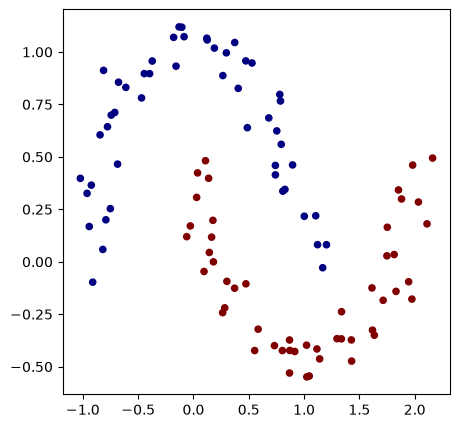

In [3]:
# more advanced demo

import numpy as np
import random
import matplotlib.pyplot as plt

np.random.seed(1337)
random.seed(1337)

from sklearn.datasets import make_moons, make_blobs

X, y = make_moons(100, noise=0.1)

y = y*2 - 1 # set y to be -1 or 1

plt.figure(figsize=(5,5))
plt.scatter(X[:,0], X[:,1], c=y, s=20, cmap='jet')

In [25]:
# loss function

model = MLP(2, [16, 16, 1])

def loss(batch_size=None):
    
    # split into batches or not, so we dont run the whole training set thru forward pass every single time
    if batch_size is None:
        Xb, yb = X, y
    else:
        ri = np.random.permutation(X.shape[0])[:batch_size]
        Xb, yb = X[ri], y[ri]
    inputs = [list(map(Value, xrow)) for xrow in Xb] # convert every datapoint to a value object, and convert into a list of lists
    
    # forward the model to get scores
    scores = list(map(model, inputs)) # pass each list (input in inputs) through the net
    
    # svm "max-margin" loss
    losses = [(1 + -yi*scorei).relu() for yi, scorei in zip(yb, scores)] # take the hinge function for all y vs ypred in the batch
    data_loss = sum(losses) * (1.0 / len(losses)) # normalise by batch size
    # L2 regularization
    # alpha = 1e-4 # tuning parameter - higher = more penalty on the weights
    # reg_loss = alpha * sum((p*p for p in model.parameters())) # including the actual ws and bs into the loss function will force the gradient descent to reduce some and even nullify some
    # total_loss = data_loss + reg_loss
    
    # also get accuracy
    accuracy = [(yi > 0) == (scorei.data > 0) for yi, scorei in zip(yb, scores)]
    return data_loss, sum(accuracy) / len(accuracy)

total_loss, acc = loss()
print(total_loss, acc)

Value(data=1.0417705117009202) 0.5


In [26]:
# training loop
for k in range(100):

    # forward
    total_loss, acc = loss()

    # backward
    model.zero_grad()
    total_loss.backward()

    # gradient descent

    learning_rate = 1.0 - 0.9 *k/100 # decaying learning rate to increase changes of convergence
    for p in model.parameters():
        p.data -= learning_rate * p.grad

    print(f"step {k}: loss = {total_loss.data}, accuracy = {acc*100}%")




step 0: loss = 1.0417705117009202, accuracy = 50.0%
step 1: loss = 0.8820749036821416, accuracy = 79.0%
step 2: loss = 1.3527818974138364, accuracy = 75.0%
step 3: loss = 0.6987026046185163, accuracy = 82.0%
step 4: loss = 0.7060924040087346, accuracy = 84.0%
step 5: loss = 0.6801587961755275, accuracy = 84.0%
step 6: loss = 0.6875072356039406, accuracy = 85.0%
step 7: loss = 0.6924591961197024, accuracy = 84.0%
step 8: loss = 0.6668458592320715, accuracy = 85.0%
step 9: loss = 0.6699087837132572, accuracy = 84.0%
step 10: loss = 0.6775162173858125, accuracy = 86.0%
step 11: loss = 0.6893160646102153, accuracy = 87.0%
step 12: loss = 0.6587354879374853, accuracy = 86.0%
step 13: loss = 0.669687817694712, accuracy = 87.0%
step 14: loss = 0.6979737844850336, accuracy = 86.0%
step 15: loss = 0.6506800475596681, accuracy = 87.0%
step 16: loss = 0.6662128715930408, accuracy = 87.0%
step 17: loss = 0.678632410376703, accuracy = 87.0%
step 18: loss = 0.6417214696834457, accuracy = 88.0%
step 

(-1.548639298268643, 1.951360701731357)

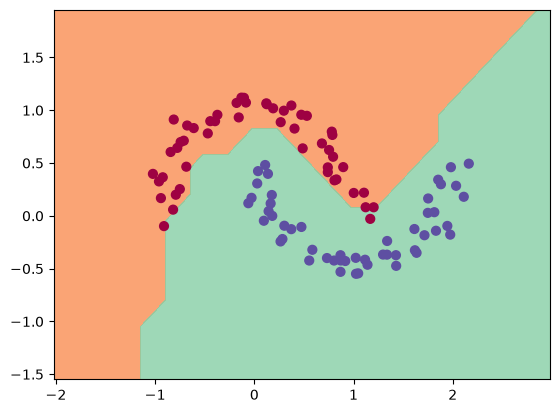

In [27]:
# visualize decision boundary

h = 0.25
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))
Xmesh = np.c_[xx.ravel(), yy.ravel()]
inputs = [list(map(Value, xrow)) for xrow in Xmesh]
scores = list(map(model, inputs))
Z = np.array([s.data > 0 for s in scores])
Z = Z.reshape(xx.shape)

fig = plt.figure()
plt.contourf(xx, yy, Z, cmap=plt.cm.Spectral, alpha=0.8)
plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.Spectral)
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())